--- Original Data Shape (With Duplicates & Nulls) ---
(215, 7)

--- Cleaned Data Shape ---
(200, 7)

--- Core Business Metrics ---
Total Sales: $243,840.94
Total Profit: $61,006.36
Total Quantity Sold: 938


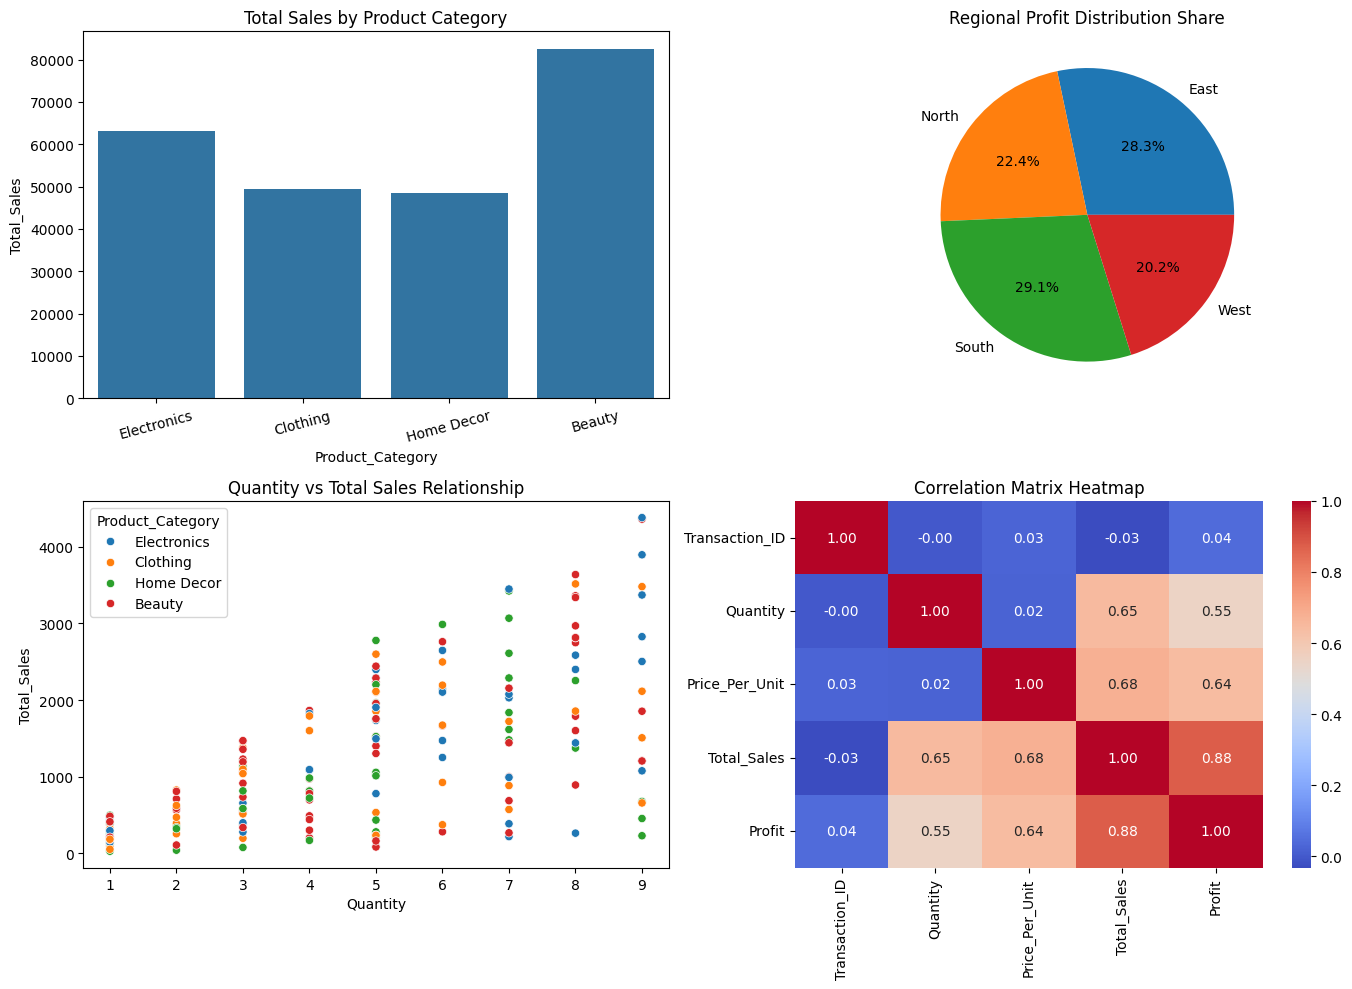

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(42)
data_size = 200

data = {
    "Transaction_ID": np.random.randint(1000, 1100, size=data_size),
    "Product_Category": np.random.choice(
        ["Electronics", "Clothing", "Home Decor", "Beauty"], size=data_size
    ),
    "Quantity": np.random.randint(1, 10, size=data_size),
    "Price_Per_Unit": np.random.uniform(10, 500, size=data_size).round(2),
    "Region": np.random.choice(["North", "South", "East", "West"], size=data_size),
}

df = pd.DataFrame(data)
df["Total_Sales"] = df["Quantity"] * df["Price_Per_Unit"]
df["Profit"] = (df["Total_Sales"] * np.random.uniform(0.1, 0.4, size=data_size)).round(
    2
)

df.loc[np.random.choice(df.index, 10), "Quantity"] = np.nan
df.loc[np.random.choice(df.index, 5), "Profit"] = np.nan
df = pd.concat([df, df.iloc[:15]], ignore_index=True)

print("--- Original Data Shape (With Duplicates & Nulls) ---")
print(df.shape)

df.drop_duplicates(inplace=True)

# Imputing missing values using median and mean strategies
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())
df["Profit"] = df["Profit"].fillna(df["Profit"].mean())

print("\n--- Cleaned Data Shape ---")
print(df.shape)

total_sales = df["Total_Sales"].sum()
total_profit = df["Profit"].sum()
total_qty = df["Quantity"].sum()

print("\n--- Core Business Metrics ---")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Quantity Sold: {int(total_qty)}")

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
sns.barplot(
    x="Product_Category", y="Total_Sales", data=df, estimator=sum, errorbar=None
)
plt.title("Total Sales by Product Category")
plt.xticks(rotation=15)

plt.subplot(2, 2, 2)
region_profit = df.groupby("Region")["Profit"].sum()
plt.pie(region_profit, labels=region_profit.index, autopct="%1.1f%%")
plt.title("Regional Profit Distribution Share")

plt.subplot(2, 2, 3)
sns.scatterplot(x="Quantity", y="Total_Sales", hue="Product_Category", data=df)
plt.title("Quantity vs Total Sales Relationship")

plt.subplot(2, 2, 4)
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix Heatmap")

plt.tight_layout()
plt.show()

--- Original Dataset Preview ---
   Study_Time_Hours  Attendance_Percentage  Previous_Score Parental_Education  \
0                 7                   67.0              62             Master   
1                 4                   66.0              68             Master   
2                 8                   62.0              82           Bachelor   
3                 5                   76.0              50           Bachelor   
4                 7                   92.0              57           Bachelor   

  Internet_Access  Final_Score  
0              No         91.7  
1             Yes         72.7  
2             Yes         89.9  
3             Yes         70.3  
4              No         87.3  


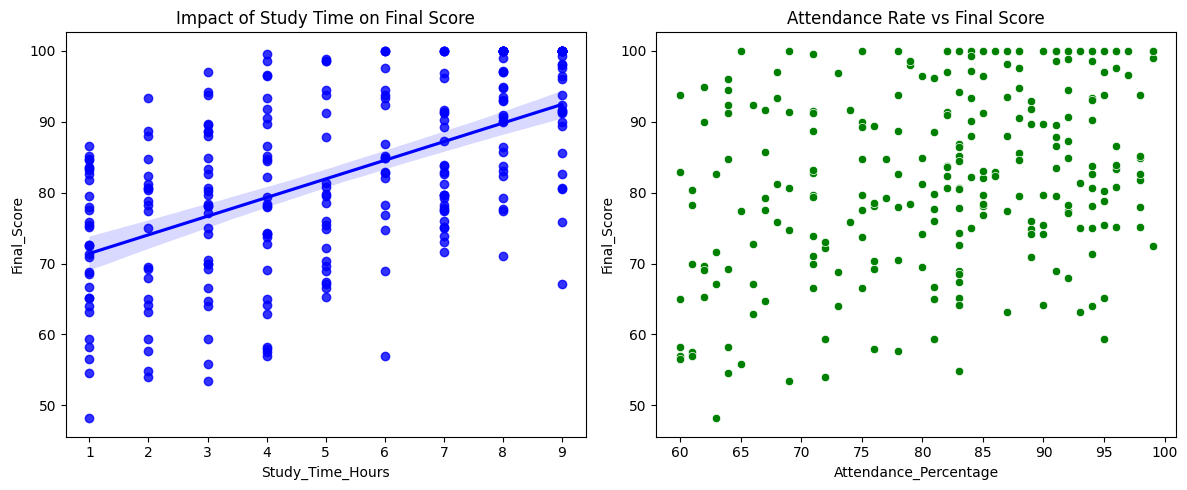


--- Predictive Model Evaluation ---
Mean Absolute Error (MAE): 3.76
Mean Squared Error (MSE): 20.52
R-squared Score (R²): 0.86

--- Feature Influence on Student Outcome ---
Study_Time_Hours: 2.68
Attendance_Percentage: 0.35
Previous_Score: 0.47
Parental_Education_High School: -1.07
Parental_Education_Master: -0.69
Internet_Access_Yes: 0.19


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

np.random.seed(42)
data_size = 250

data = {
    "Study_Time_Hours": np.random.randint(1, 10, size=data_size),
    "Attendance_Percentage": np.random.randint(60, 100, size=data_size),
    "Previous_Score": np.random.randint(40, 100, size=data_size),
    "Parental_Education": np.random.choice(
        ["High School", "Bachelor", "Master"], size=data_size
    ),
    "Internet_Access": np.random.choice(["Yes", "No"], size=data_size),
}

df = pd.DataFrame(data)

df["Final_Score"] = (
    (df["Study_Time_Hours"] * 3)
    + (df["Attendance_Percentage"] * 0.4)
    + (df["Previous_Score"] * 0.5)
    + np.random.normal(0, 5, size=data_size)
)
df["Final_Score"] = df["Final_Score"].clip(0, 100).round(1)

df.loc[np.random.choice(df.index, 12), "Attendance_Percentage"] = np.nan

print("--- Original Dataset Preview ---")
print(df.head())

df["Attendance_Percentage"] = df["Attendance_Percentage"].fillna(
    df["Attendance_Percentage"].median()
)

df = pd.get_dummies(
    df, columns=["Parental_Education", "Internet_Access"], drop_first=True
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.regplot(x="Study_Time_Hours", y="Final_Score", data=df, color="blue")
plt.title("Impact of Study Time on Final Score")

plt.subplot(1, 2, 2)
sns.scatterplot(x="Attendance_Percentage", y="Final_Score", data=df, color="green")
plt.title("Attendance Rate vs Final Score")

plt.tight_layout()
plt.show()

X = df.drop(columns=["Final_Score"])
y = df["Final_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- Predictive Model Evaluation ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score (R²): {r2:.2f}")

features = X.columns
coefficients = model.coef_
print("\n--- Feature Influence on Student Outcome ---")
for feat, coeff in zip(features, coefficients):
    print(f"{feat}: {coeff:.2f}")

--- Initial Housing Dataset Preview ---
   Square_Feet  Bedrooms  House_Age_Years Location_Type      Price
0       1660.0         1                2      Suburban  341845.57
1       2094.0         5               12      Suburban  469755.74
2       1930.0         4               27      Suburban  400379.59
3       1895.0         5               48         Rural  369788.53
4       2438.0         3               24         Rural  440394.37


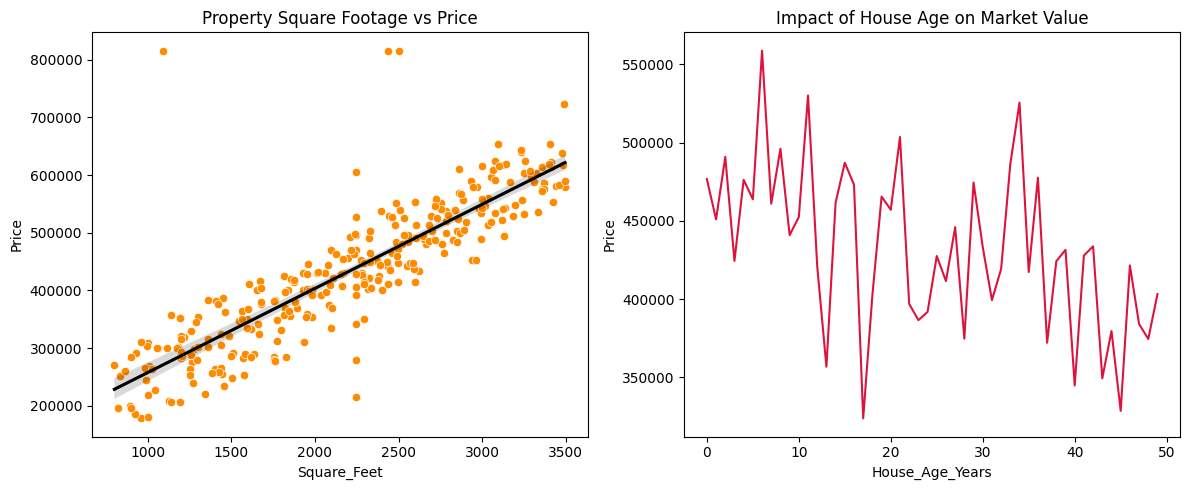


--- Housing Regression Model Performance ---
Mean Absolute Error (MAE): $18,841.71
Root Mean Squared Error (RMSE): $37,427.17
R-squared Accuracy Score (R²): 0.88

--- Structural Feature Weights (Coefficients) ---
Square_Feet: 147.34
Bedrooms: 23608.15
House_Age_Years: -1135.24
Location_Type_Suburban: 11321.33
Location_Type_Urban: 1616.93


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

np.random.seed(42)
data_size = 300

data = {
    "Square_Feet": np.random.randint(800, 3500, size=data_size),
    "Bedrooms": np.random.randint(1, 6, size=data_size),
    "House_Age_Years": np.random.randint(0, 50, size=data_size),
    "Location_Type": np.random.choice(["Urban", "Suburban", "Rural"], size=data_size),
}

df = pd.DataFrame(data)

df["Price"] = (
    (df["Square_Feet"] * 150)
    + (df["Bedrooms"] * 25000)
    - (df["House_Age_Years"] * 1200)
    + np.random.normal(50000, 15000, size=data_size)
)
df["Price"] = df["Price"].round(2)

df.loc[np.random.choice(df.index, 8), "Square_Feet"] = np.nan
df.loc[np.random.choice(df.index, 3), "Price"] = (
    df["Price"] * 5
)

print("--- Initial Housing Dataset Preview ---")
print(df.head())

df["Square_Feet"] = df["Square_Feet"].fillna(df["Square_Feet"].median())

Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df["Price"] = np.clip(df["Price"], lower_bound, upper_bound)

df = pd.get_dummies(df, columns=["Location_Type"], drop_first=True)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(x="Square_Feet", y="Price", data=df, color="darkorange")
sns.regplot(x="Square_Feet", y="Price", data=df, scatter=False, color="black")
plt.title("Property Square Footage vs Price")

plt.subplot(1, 2, 2)
sns.lineplot(x="House_Age_Years", y="Price", data=df, color="crimson", errorbar=None)
plt.title("Impact of House Age on Market Value")

plt.tight_layout()
plt.show()

X = df.drop(columns=["Price"])
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- Housing Regression Model Performance ---")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared Accuracy Score (R²): {r2:.2f}")

print("\n--- Structural Feature Weights (Coefficients) ---")
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef:.2f}")